# 📊 Capítulo 2: Contrarian Investing
*Comprar cuando nadie quiere — Reversión a la media con filtros cuantitativos*

**Estrategia (v2):** cada mes se rellenan los *slots* libres (máx. `TOP_N_PERDEDORES`, 1/N del capital cada uno) con los ETFs de peor rentabilidad a 12 meses que cumplan dos filtros: drawdown desde máximos de 52 semanas ≤ umbral y RSI(14, Wilder) ≤ umbral. Cada posición se mantiene `HOLDING_MESES` meses (o hasta su stop-loss, si está activo). Los slots vacíos se aparcan en SHV (cash con rentabilidad real).

**Supuestos de ejecución (v3):** la señal usa datos hasta t-1 y se ejecuta al cierre de t (`RETRASO_SENAL_DIAS`). Opcionales: filtro de régimen SPY > SMA200, excluir SPY de los candidatos y comparativa de escenarios con referencias SPY y SHV (Bloque 10), barrido de parámetros IS/OOS (Bloque 11) y **test placebo** de selección (Bloque 12).

**Perfiles:** `defensivo` (DD ≤ -30 %, RSI ≤ 30, 6 meses, sin stop) y `agresivo` (DD ≤ -15 %, RSI ≤ 45, 3 meses, stop -10 %). Se elige en el Bloque 0 con `PERFIL`.

**Universo:** 16 ETFs candidatos + SHV (cash): SPY, QQQ, IWM, los 9 SPDR sectoriales históricos (XLK, XLF, XLE, XLV, XLI, XLP, XLU, XLB, XLY), EFA, EEM, TLT y GLD.

**Objetivo:** contrastar con datos si el contrarian cuantitativo (comprar lo que ha caído mucho cuando el pánico es medible) aporta algo frente al buy & hold. El capítulo **no presupone el resultado**: el Bloque 10 lo genera a partir de las métricas reales de la ejecución.


## BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA

In [1]:
# %% [markdown]
# # 📊 Capítulo 2: Contrarian Investing
# *Comprar cuando nadie quiere — Reversión a la media con filtros cuantitativos*
# 
# **Estrategia:** Ranking mensual de los 5 ETFs con peor rentabilidad a 12 meses, filtrados por drawdown ≥30% desde máximos y RSI(14) <30. Holding period de 6 meses. Capital no asignado en SHV (cash).
# 
# **Universo:** 19 ETFs sectoriales y de factores (SPDRs, iShares, Vanguard): XLK, XLF, XLE, XLV, XLI, XLP, XLU, XLB, XLY, XLC, XLRE, IWM, IWF, IWD, EFA, EEM, GLD, VNQ, SHV.
# 
# **Objetivo:** Demostrar que el contrarian puro (comprar "lo que más baja") es una trampa mortal, pero que añadir filtros cuantitativos de drawdown y RSI convierte la estrategia en un satélite defensivo con alpha positivo y drawdown reducido, complementando una cartera core ortodoxa.

# %%
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — CONTRARIAN INVESTING
# ==============================================================================

# --- Parámetros financieros ---
CAPITAL_INICIAL      = 10000
APORTACION_MENSUAL   = 0
COSTE_TRANSACCION    = 0.001       # 0.1% por operación (compra o venta); ver Bloque 6
FREQ_REBALANCEO      = 'M'         # Revisión mensual
BENCHMARK            = 'SPY'

# --- Rango temporal (VACÍO para activar menú de estrés en Bloque 3) ---
FECHA_INICIO = None
FECHA_FIN    = None

# --- Parámetros específicos de la estrategia Contrarian ---
PERFILES = {
    'defensivo': dict(umbral_drawdown=-0.30, umbral_rsi=30.0, holding_meses=6, stop_loss_pct=None),
    'agresivo':  dict(umbral_drawdown=-0.15, umbral_rsi=45.0, holding_meses=3, stop_loss_pct=-0.10),
}
PERFIL = 'agresivo'                 # 'defensivo' | 'agresivo'  (= los parámetros que venías usando)

TOP_N_PERDEDORES     = 5            # nº de slots (cada uno pesa 1/N; lo no usado va a SHV)
CASH_TICKER          = 'SHV'        # Letras del Tesoro: parking de los slots vacíos

# Opcionales (0/1 = comportamiento básico). Útiles para el barrido de parámetros:
RSI_LOOKBACK_DIAS    = 1            # RSI mínimo de los últimos N días (1 = solo el día de decisión)
ESTABILIZACION_DIAS  = 0            # >0: exige rentabilidad > 0 en los últimos N días (no comprar mientras cae)
COOLDOWN_STOP_MESES  = 3            # meses sin recomprar un ETF tras un stop-loss

# Supuestos de ejecución y filtros de régimen (v3)
RETRASO_SENAL_DIAS         = 1      # 1 = señal con cierre de t-1, ejecución al cierre de t. 0 = señal y ejecución en el mismo cierre (optimista)
FILTRO_REGIMEN             = False  # True: solo se compra si SPY > SMA(SMA_REGIMEN)
SMA_REGIMEN                = 200
REGIMEN_CIERRA_POSICIONES  = False  # True: además se liquida lo abierto al perder el régimen
EXCLUIR_SPY_DE_CANDIDATOS  = False  # True: SPY solo sirve de benchmark/régimen, no se compra

_P = PERFILES[PERFIL]
UMBRAL_DRAWDOWN = _P['umbral_drawdown']
UMBRAL_RSI      = _P['umbral_rsi']
HOLDING_MESES   = _P['holding_meses']
STOP_LOSS_PCT   = _P['stop_loss_pct']   # None = sin stop. Se evalúa en cada decisión (mensual)

# --- Ventana mínima necesaria para los indicadores (en días bursátiles) ---
# Rentabilidad 12m = 252 días + Drawdown 52s = 252 días + RSI(14) = 14 días
# Añadimos un buffer de seguridad del 20%
VENTANA_MINIMA_DIAS  = int(252 * 1.20)  # ≈ 302 días

# --- Rutas portables ---
RUTA_ENTRADA_R4 = None
RUTA_SALIDA_CSV = None

# --- Universo de activos: ETFs sectoriales y de factores ---
# --- Universo de activos: ETFs con histórico largo (desde 2000-2004) ---
UNIVERSO_CONTRARIAN = {
    # --- Grandes caps y broad market (existentes desde 1993-2000) ---
    'broad_market': {
        'SPDR S&P 500':           {'isin': 'SPY',  'ticker': 'SPY'},   # Desde 1993
        'Invesco QQQ':            {'isin': 'QQQ',  'ticker': 'QQQ'},   # Desde 1999
        'Russell 2000 Small Cap': {'isin': 'IWM',  'ticker': 'IWM'},   # Desde 2000
    },
    # --- Sectoriales SPDR antiguos (existentes desde 1998) ---
    'sectoriales_antiguos': {
        'Technology SPDR':        {'isin': 'XLK',  'ticker': 'XLK'},   # Desde 1998
        'Financials SPDR':        {'isin': 'XLF',  'ticker': 'XLF'},   # Desde 1998
        'Energy SPDR':            {'isin': 'XLE',  'ticker': 'XLE'},   # Desde 1998
        'Healthcare SPDR':        {'isin': 'XLV',  'ticker': 'XLV'},   # Desde 1998
        'Industrial SPDR':        {'isin': 'XLI',  'ticker': 'XLI'},   # Desde 1998
        'Consumer Staples SPDR':  {'isin': 'XLP',  'ticker': 'XLP'},   # Desde 1998
        'Utilities SPDR':         {'isin': 'XLU',  'ticker': 'XLU'},   # Desde 1998
        'Materials SPDR':         {'isin': 'XLB',  'ticker': 'XLB'},   # Desde 1998
        'Consumer Disc SPDR':     {'isin': 'XLY',  'ticker': 'XLY'},   # Desde 1998
    },
    # --- Internacionales y bonos (existentes desde 2001-2002) ---
    'internacional_bonos': {
        'MSCI EAFE Developed':    {'isin': 'EFA',  'ticker': 'EFA'},   # Desde 2001
        'MSCI Emerging Markets':  {'isin': 'EEM',  'ticker': 'EEM'},   # Desde 2003
        'iShares 20+ Year Treasury': {'isin': 'TLT', 'ticker': 'TLT'}, # Desde 2002
    },
    # --- Alternativos (existentes desde 2004) ---
    'alternativos': {
        'Gold ETF':               {'isin': 'GLD',  'ticker': 'GLD'},   # Desde 2004
    },
    # --- Cash proxy ---
    'cash': {
        'Short Treasury ETF':    {'isin': 'SHV',  'ticker': 'SHV'},
    },
}

print("✅ Configuración Contrarian cargada:")
print(f"   • Capital inicial: {CAPITAL_INICIAL:,.0f} €")
print(f"   • Universo: {len([a for cat in UNIVERSO_CONTRARIAN.values() for a in cat])} ETFs")
print(f"   • Perfil: {PERFIL}")
print(f"   • Slots (top perdedores): {TOP_N_PERDEDORES}")
print(f"   • Filtro drawdown: ≤ {UMBRAL_DRAWDOWN:.0%}")
print(f"   • Filtro RSI: ≤ {UMBRAL_RSI}")
print(f"   • Holding period: {HOLDING_MESES} meses")
print(f"   • Stop-loss: {f'{STOP_LOSS_PCT:.0%}' if STOP_LOSS_PCT is not None else 'desactivado'}")
print(f"   • Retraso de señal: {RETRASO_SENAL_DIAS} d | Régimen: {'ON' if FILTRO_REGIMEN else 'OFF'} | SPY candidato: {'no' if EXCLUIR_SPY_DE_CANDIDATOS else 'sí'}")
print(f"   • Cash proxy: {CASH_TICKER}")
print(f"   • Benchmark: {BENCHMARK}")
print(f"   • Ventana mínima requerida: {VENTANA_MINIMA_DIAS} días bursátiles")

✅ Configuración Contrarian cargada:
   • Capital inicial: 10,000 €
   • Universo: 17 ETFs
   • Perfil: agresivo
   • Slots (top perdedores): 5
   • Filtro drawdown: ≤ -15%
   • Filtro RSI: ≤ 45.0
   • Holding period: 3 meses
   • Stop-loss: -10%
   • Retraso de señal: 1 d | Régimen: OFF | SPY candidato: sí
   • Cash proxy: SHV
   • Benchmark: SPY
   • Ventana mínima requerida: 302 días bursátiles


## BLOQUE 1: ENTORNO E IMPORTACIONES

In [2]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 1: ENTORNO E IMPORTACIONES
# # ==============================================================================

# %%
# ==============================================================================
# BLOQUE 1: ENTORNO E IMPORTACIONES
# ==============================================================================

# --- Aviso legal ---
print("="*70)
print("⚠️  AVISO LEGAL")
print("="*70)
print("""
Este notebook tiene fines EXCLUSIVAMENTE EDUCATIVOS y de investigación
cuantitativa. NO constituye asesoramiento financiero ni recomendación de
inversión. El rendimiento pasado no garantiza resultados futuros.
Operar en mercados financieros conlleva riesgo de pérdida de capital.
""")
print("="*70)

# --- Detección de entorno ---
import sys
import os
import warnings
warnings.filterwarnings('ignore')

IN_COLAB = "google.colab" in sys.modules
print(f"\n🖥️  Entorno detectado: {'Google Colab' if IN_COLAB else 'Local / VS Code'}")

# --- Importaciones estándar ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from pathlib import Path

# --- Búsqueda dinámica de la carpeta 'core' ---
def buscar_core():
    """Busca la carpeta 'core' subiendo desde el notebook."""
    try:
        import ipykernel
        try:
            from jupyter_server import serverapp as app_module
        except ImportError:
            from notebook import notebookapp as app_module
        import json, re, urllib.request
        connection_file = os.path.basename(ipykernel.get_connection_file())
        match = re.search(r'kernel-(.*)\.json', connection_file)
        if match:
            kernel_id = match.group(1)
            for srv in app_module.list_running_servers():
                try:
                    url = srv['url'] + 'api/sessions'
                    token = srv.get('token', '')
                    headers = {'Authorization': f'token {token}'} if token else {}
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=2) as resp:
                        sessions = json.loads(resp.read())
                    for sess in sessions:
                        if sess.get('kernel', {}).get('id') == kernel_id:
                            ruta_nb = os.path.join(srv['root_dir'], sess['notebook']['path'])
                            ruta_dir = os.path.dirname(os.path.abspath(ruta_nb))
                            # Subir hasta encontrar 'core'
                            actual = Path(ruta_dir)
                            for parent in [actual] + list(actual.parents):
                                if (parent / 'core').exists():
                                    return str(parent / 'core')
                except Exception:
                    continue
    except Exception:
        pass
    # Fallback: asumir estructura estándar
    for ruta in ['../core', '../../core', './core']:
        if os.path.isdir(ruta):
            return os.path.abspath(ruta)
    return None

# [parche-colab] En Colab solo se carga el .ipynb: se clona el repo para disponer de 'core/'
if "google.colab" in sys.modules:
    import subprocess
    _REPO = "/content/Estrategias_No_Convencionales"
    if not os.path.isdir(os.path.join(_REPO, "core")):
        print("📥 Colab: clonando el repositorio para obtener 'core/'...")
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/akitxu/Estrategias_No_Convencionales.git", _REPO], check=True)
    os.chdir(os.path.join(_REPO, "notebooks"))   # así buscar_core() encuentra '../core'

RUTA_CORE = buscar_core()
if RUTA_CORE and os.path.isdir(RUTA_CORE):
    sys.path.insert(0, os.path.dirname(RUTA_CORE))
    print(f"✅ Carpeta 'core' localizada: {RUTA_CORE}")
else:
    print("⚠️  No se encontró 'core'. Asegúrate de que la estructura del proyecto es correcta.")

# --- Importación segura de módulos ---
try:
    from core import (
        GestorProyecto,
        GestorDatos,
        MotorBacktest,
        MotorBacktestDinamico,
        CalculadorMetricas,
        CalculadorMetricasExtras,
        GeneradorInformes
    )
    print("✅ Módulos del motor importados correctamente:")
    print("   • GestorProyecto, GestorDatos")
    print("   • MotorBacktest, MotorBacktestDinamico (NUEVO)")
    print("   • CalculadorMetricas, CalculadorMetricasExtras (NUEVO)")
    print("   • GeneradorInformes")
except ImportError as e:
    print(f"❌ Error importando módulos: {e}")
    print("   Verifica que los archivos backtest_dinamico.py y metricas_extras.py")
    print("   existen en la carpeta core/ y están actualizados.")
    raise

# --- Asignación automática de rutas ---
BASE_DIR = os.path.dirname(RUTA_CORE) if RUTA_CORE else os.getcwd()
print(f"\n📂 BASE_DIR del proyecto: {BASE_DIR}")

⚠️  AVISO LEGAL

Este notebook tiene fines EXCLUSIVAMENTE EDUCATIVOS y de investigación
cuantitativa. NO constituye asesoramiento financiero ni recomendación de
inversión. El rendimiento pasado no garantiza resultados futuros.
Operar en mercados financieros conlleva riesgo de pérdida de capital.


🖥️  Entorno detectado: Local / VS Code
✅ Carpeta 'core' localizada: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
✅ Módulos del motor importados correctamente:
   • GestorProyecto, GestorDatos
   • MotorBacktest, MotorBacktestDinamico (NUEVO)
   • CalculadorMetricas, CalculadorMetricasExtras (NUEVO)
   • GeneradorInformes

📂 BASE_DIR del proyecto: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales


## BLOQUE 2: LIMPIEZA DE DIRECTORIOS

In [3]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 2: LIMPIEZA DE DIRECTORIOS
# # ==============================================================================

# %%
# ==============================================================================
# BLOQUE 2: LIMPIEZA DE DIRECTORIOS (Primer Menú)
# ==============================================================================

gestor_proyecto = GestorProyecto(base_dir_manual=BASE_DIR)
gestor_proyecto.imprimir_resumen()

# Menú de limpieza
gestor_proyecto.menu_limpieza_directorios()

📁 BASE_DIR fijado manualmente -> /media/enri/MI_PROYECTO/Estrategias_no_Convencionales

🔍 ENTORNO CONFIGURADO
📂 Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📁 CORE                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
📁 CHAPTERS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/chapters
📁 LOGS                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/logs
📁 DATOS               : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos
📁 OUTPUTS             : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs
📁 CARTERAS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/carteras
📁 DATOS_CSV           : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_csv
📁 DATOS_FI_GESTORA    : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_gestora
📁 DATOS_FI_INVESTING  : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_investing
📁 DATOS_FI_MYI


¿Qué directorios deseas VACIAR? (ej: 3,5,7 / 'todos' / 'ninguno'):  2



🧹 Iniciando limpieza...
   🗑️  Vaciando 'CHAPTERS'...
      ✅ 'CHAPTERS' limpiado.


## BLOQUE 3: GESTIÓN DE FECHAS (MENÚ DE ESTRÉS)

In [4]:
## %% [markdown]
# # ==============================================================================
# # BLOQUE 3: GESTIÓN DE FECHAS (MENÚ DE ESTRÉS)
# # ==============================================================================

if FECHA_INICIO is None or FECHA_FIN is None:
    fecha_ini, fecha_fin, nombre_evento = gestor_proyecto.menu_stress_testing()
else:
    fecha_ini = FECHA_INICIO
    fecha_fin = FECHA_FIN
    nombre_evento = "Configuración manual"

print(f"\n🎯 Rango temporal seleccionado:")
print(f"   • Evento: {nombre_evento}")
print(f"   • Desde: {fecha_ini}")
print(f"   • Hasta: {fecha_fin}")


📉 ANÁLISIS DE ESTRÉS (STRESS TESTING)
  1. Crisis Punto Com (2000-2002)
  2. Crisis Financiera Mundial (2007-2009)
  3. Crisis Deuda Soberana (2010-2012)
  4. Crisis Financiera China (2015-2016)
  5. Crisis COVID-19 (2020)
  6. Subida Tipos / Inflación (2022-2023)
  7. Periodo Personalizado
  8. Histórico Completo (1999-Hoy)



Introduce tu elección (1-8) [Por defecto 8]:  7
  Fecha inicio (YYYY-MM-DD):  2007-01-04
  Fecha fin (YYYY-MM-DD):  2026-08-15



🎯 Evento: Periodo Personalizado | Inicio: 2007-01-04 | Fin: 2026-08-15


🎯 Rango temporal seleccionado:
   • Evento: Periodo Personalizado
   • Desde: 2007-01-04
   • Hasta: 2026-08-15


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [5]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 4: MENÚ DEL GESTOR DE DATOS
# # ==============================================================================

# %%
# ==============================================================================
# BLOQUE 4: MENÚ DEL GESTOR DE DATOS
# ==============================================================================

# Inicializar GestorDatos con las fechas del Bloque 3 (sin warm-up todavía)
gestor = GestorDatos(
    diccionario_datos=UNIVERSO_CONTRARIAN,
    fecha_inicio=fecha_ini,    # ← Viene del menú de estrés del Bloque 3
    fecha_fin=fecha_fin,       # ← Viene del menú de estrés del Bloque 3
    gestor_proyecto=gestor_proyecto
)

print(f"\n📊 GestorDatos inicializado con {len(UNIVERSO_CONTRARIAN)} categorías de activos.")
print(f"   • Período: {fecha_ini} → {fecha_fin}")
print(f"   • Evento: {nombre_evento}")
print("   Ejecutando menú de importación/descarga...\n")

# Ejecutar menú interactivo
continuar = gestor.menu()

if not continuar:
    print("⛔ Usuario canceló. Abortando notebook.")
else:
    print("\n✅ Datos preparados para el motor.")
    


📊 GestorDatos inicializado con 5 categorías de activos.
   • Período: 2007-01-04 → 2026-08-15
   • Evento: Periodo Personalizado
   Ejecutando menú de importación/descarga...


 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  1



🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 17 activos...

   📊 SPDR S&P 500
      ✅ Descargado con ticker: SPY

   📊 Invesco QQQ
      ✅ Descargado con ticker: QQQ

   📊 Russell 2000 Small Cap
      ✅ Descargado con ticker: IWM

   📊 Technology SPDR
      ✅ Descargado con ticker: XLK

   📊 Financials SPDR
      ✅ Descargado con ticker: XLF

   📊 Energy SPDR
      ✅ Descargado con ticker: XLE

   📊 Healthcare SPDR
      ✅ Descargado con ticker: XLV

   📊 Industrial SPDR
      ✅ Descargado con ticker: XLI

   📊 Consumer Staples SPDR
      ✅ Descargado con ticker: XLP

   📊 Utilities SPDR
      ✅ Descargado con ticker: XLU

   📊 Materials SPDR
      ✅ Descargado con ticker: XLB

   📊 Consumer Disc SPDR
      ✅ Descargado con ticker: XLY

   📊 MSCI EAFE Developed
      ✅ Descargado con ticker: EFA

   📊 MSCI Emerging Markets
      ✅ Descargado con ticker: EEM

   📊 iShares 20+ Year Treasury
      ✅ Descargado con ticker: TLT

   📊 Gold ETF
      ✅ Descar


Presiona Enter para continuar... 



 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  6



✅ Datos aceptados para el backtest.
📝 No hay Excel cargado. Generando cartera automática (60/40) desde el diccionario...

🧼 INFORME DE LIMPIEZA DE DATOS


,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,SPDR S&P 500,SPY,4934,2007-01-04,2026-08-14,CSV
1,Invesco QQQ,QQQ,4934,2007-01-04,2026-08-14,CSV
2,Russell 2000 Small Cap,IWM,4934,2007-01-04,2026-08-14,CSV
3,Technology SPDR,XLK,4934,2007-01-04,2026-08-14,CSV
4,Financials SPDR,XLF,4934,2007-01-04,2026-08-14,CSV
5,Energy SPDR,XLE,4934,2007-01-04,2026-08-14,CSV
6,Healthcare SPDR,XLV,4934,2007-01-04,2026-08-14,CSV
7,Industrial SPDR,XLI,4934,2007-01-04,2026-08-14,CSV
8,Consumer Staples SPDR,XLP,4934,2007-01-04,2026-08-14,CSV
9,Utilities SPDR,XLU,4934,2007-01-04,2026-08-14,CSV


✅ 17 activos alineados para el Motor Backtest.


✅ Datos preparados para el motor.


##  BLOQUE 5: PREPARACIÓN DE PESOS — LÓGICA CONTRARIAN 

### Algoritmo Contrarian v3 (definición)
Sustituye a `GestorDatos.contrarian_ranking`. Incluye: slots de 1/N, cash en SHV, entradas escalonadas, stop-loss real, pesos derivados (sin rotación espuria), **retraso de señal**, **filtro de régimen** opcional, exclusión de SPY opcional y utilidades de comparativa/barrido y **test placebo**.

In [6]:
# %%
# ==============================================================================
# BLOQUE 5a: ALGORITMO CONTRARIAN v3.2 (definiciones, comparativa, barrido y placebo)
# ==============================================================================
import itertools
from collections import Counter
import numpy as np
import pandas as pd


def _rsi_wilder(px: pd.DataFrame, periodo: int = 14) -> pd.DataFrame:
    """RSI de Wilder (suavizado exponencial alpha=1/periodo), vectorizado y causal."""
    delta = px.diff()
    ganancia = delta.clip(lower=0.0)
    perdida = (-delta).clip(lower=0.0)
    ag = ganancia.ewm(alpha=1.0 / periodo, adjust=False, min_periods=periodo).mean()
    al = perdida.ewm(alpha=1.0 / periodo, adjust=False, min_periods=periodo).mean()
    rs = ag / al.replace(0.0, np.nan)
    rsi = 100.0 - 100.0 / (1.0 + rs)
    rsi = rsi.where(~((al == 0.0) & ag.notna()), 100.0)   # sin pérdidas -> RSI 100
    return rsi


def crear_generador_contrarian(
    precios: pd.DataFrame,
    cash_columna=None,
    top_n: int = 5,
    umbral_drawdown: float = -0.30,
    umbral_rsi: float = 30.0,
    holding_meses: int = 6,
    stop_loss_pct=None,
    cooldown_stop_meses: int = 3,
    rsi_lookback_dias: int = 1,
    estabilizacion_dias: int = 0,
    retraso_senal_dias: int = 1,
    columna_spy=None,
    usar_regimen: bool = False,
    sma_regimen: int = 200,
    regimen_cierra_posiciones: bool = False,
    excluir_spy: bool = False,
    fecha_inicio_operativa=None,
    ventana: int = 252,
    periodo_rsi: int = 14,
    placebo=None,
    verbose: bool = True,
):
    """
    Contrarian v3 para MotorBacktestDinamico.

    Novedades respecto a v2:
      retraso_senal_dias (def. 1): la señal usa datos hasta t-L y se ejecuta al cierre de t. Con 0 se
          reproduce el supuesto optimista anterior (señal y ejecución en el mismo cierre). El stop-loss
          se evalúa con el precio de t-L; la rentabilidad registrada en el log usa el precio real de t.
      usar_regimen: solo se compra si SPY > SMA(sma_regimen) (evaluado en t-L). Con
          regimen_cierra_posiciones=True además se liquidan las posiciones abiertas al perder el régimen.
      excluir_spy: SPY deja de ser candidato (sigue disponible como referencia de régimen y benchmark).

      placebo: dict(calendario={fecha: n_entradas}, rng=np.random.Generator). Si se pasa, las ENTRADAS se
          eligen al azar entre los activos con datos válidos (en lugar de por filtros y ranking), respetando
          el calendario de entradas dado. Todo lo demás (slots, holding, stop, régimen, costes) es idéntico.

    Resto de comportamiento (heredado de v2): slots de 1/top_n, capital sin asignar en cash (SHV),
    entradas escalonadas con holding por posición, pesos derivados (sin rotación espuria), no opera antes de
    fecha_inicio_operativa, registro de operaciones en estado['operaciones'].
    """
    precios = precios.copy()
    activos = list(precios.columns)
    if (usar_regimen or excluir_spy) and columna_spy is None:
        raise ValueError("usar_regimen / excluir_spy requieren columna_spy (columna de SPY en 'precios').")
    excluidos = {columna_spy} if (excluir_spy and columna_spy) else set()
    candidatos = [a for a in activos if a != cash_columna and a not in excluidos]
    px = precios[candidatos]
    L = max(0, int(retraso_senal_dias))

    ret12m = px.pct_change(ventana)
    dd = px / px.rolling(ventana, min_periods=ventana).max() - 1.0
    rsi = _rsi_wilder(px, periodo_rsi)
    rsi_ref = rsi.rolling(max(1, rsi_lookback_dias), min_periods=1).min()
    if estabilizacion_dias > 0:
        estable = px.pct_change(estabilizacion_dias) > 0.0
    else:
        estable = pd.DataFrame(True, index=px.index, columns=px.columns)
    valido = ret12m.notna() & dd.notna() & rsi.notna()
    senal_base = valido & (dd <= umbral_drawdown) & (rsi_ref <= umbral_rsi) & estable

    if usar_regimen:
        pr = precios[columna_spy]
        regimen_ok = pr > pr.rolling(sma_regimen, min_periods=sma_regimen).mean()
    else:
        regimen_ok = pd.Series(True, index=precios.index)

    # --- Retraso de señal: todo lo que decide t usa información hasta t-L ---
    def _lag(obj, fill):
        return obj.shift(L, fill_value=fill) if L > 0 else obj
    senal_L = _lag(senal_base, False)
    valido_L = _lag(valido, False)
    regimen_L = _lag(regimen_ok, False)
    ret12m_L = ret12m.shift(L) if L > 0 else ret12m
    px_L = precios.shift(L) if L > 0 else precios
    senal_ef = senal_L & regimen_L.values[:, None]

    f_ini = pd.Timestamp(fecha_inicio_operativa) if fecha_inicio_operativa is not None else None
    slot = 1.0 / top_n

    def _meses(a, b):
        return (b.year - a.year) * 12 + (b.month - a.month)

    def generador_pesos(fecha_actual, precios_hist, rent_hist, estado):
        pesos = {a: 0.0 for a in activos}
        estado.setdefault('posiciones', {})
        estado.setdefault('bloqueados', {})
        estado.setdefault('operaciones', [])
        estado.setdefault('pesos_ult', None)
        estado.setdefault('fecha_ult', None)

        if (f_ini is not None and fecha_actual < f_ini) or fecha_actual not in precios.index:
            return pesos, estado
        if 'fecha_primera_decision' not in estado:
            # El periodo evaluado empieza cuando los indicadores ya son válidos (no antes): el primer año
            # de calentamiento no se cuenta como 'rendimiento' de la estrategia.
            if not bool(valido_L.loc[fecha_actual].any()):
                return pesos, estado
            estado['fecha_primera_decision'] = fecha_actual

        pos = estado['posiciones']

        # 1) Pesos derivados (drift) desde la última decisión = lo que el motor tiene realmente
        if estado['pesos_ult'] is None:
            w = {a: 0.0 for a in activos}
            if cash_columna:
                w[cash_columna] = 1.0
        else:
            p0 = precios.loc[estado['fecha_ult']]
            p1 = precios.loc[fecha_actual]
            val = {a: estado['pesos_ult'][a] * (p1[a] / p0[a]) for a in activos}
            cash_idle = 1.0 - sum(estado['pesos_ult'].values())
            tot = sum(val.values()) + cash_idle
            w = {a: v / tot for a, v in val.items()}

        def _salir(a, motivo):
            info = pos[a]
            rend_real = precios.at[fecha_actual, a] / info['precio_entrada'] - 1.0   # precio de ejecución (t)
            estado['operaciones'].append({
                'activo': a, 'entrada': info['entrada'], 'salida': fecha_actual,
                'dias': (fecha_actual - info['entrada']).days,
                'motivo': motivo, 'beneficio': rend_real,
            })
            if cash_columna:
                w[cash_columna] += w[a]
            w[a] = 0.0
            del pos[a]

        regimen_malo = usar_regimen and not bool(regimen_L.at[fecha_actual])

        # 2) Salidas: régimen (opcional), stop-loss (evaluado con precio t-L) y holding
        for a in list(pos):
            info = pos[a]
            p_dec = px_L.at[fecha_actual, a]
            p_dec = precios.at[fecha_actual, a] if pd.isna(p_dec) else p_dec
            rend_dec = p_dec / info['precio_entrada'] - 1.0
            if regimen_cierra_posiciones and regimen_malo:
                _salir(a, 'regimen')
            elif stop_loss_pct is not None and rend_dec <= stop_loss_pct:
                estado['bloqueados'][a] = fecha_actual
                _salir(a, 'stop-loss')
            elif _meses(info['entrada'], fecha_actual) >= holding_meses:
                _salir(a, 'holding')

        # 3) Entradas: slots libres con los peores 12m (a t-L) que pasen filtros y régimen
        libres = top_n - len(pos)
        if libres > 0 and not regimen_malo:
            def _bloqueado(a):
                return a in estado['bloqueados'] and _meses(estado['bloqueados'][a], fecha_actual) < cooldown_stop_meses
            if placebo is not None:
                n_obj = min(libres, placebo['calendario'].get(fecha_actual, 0))
                pool = [a for a in candidatos
                        if a not in pos and bool(valido_L.at[fecha_actual, a]) and not _bloqueado(a)]
                elegidos = ([str(x) for x in placebo['rng'].choice(pool, size=min(n_obj, len(pool)), replace=False)]
                            if n_obj > 0 and pool else [])
            else:
                cand = []
                for a in candidatos:
                    if a in pos or not senal_ef.at[fecha_actual, a] or _bloqueado(a):
                        continue
                    cand.append((ret12m_L.at[fecha_actual, a], a))
                cand.sort()
                elegidos = [a for _, a in cand[:libres]]
            for a in elegidos:
                disponible = w[cash_columna] if cash_columna else 1.0 - sum(w.values())
                monto = min(slot, max(disponible, 0.0))
                if monto <= 1e-9:
                    break
                w[a] += monto
                if cash_columna:
                    w[cash_columna] -= monto
                pos[a] = {'entrada': fecha_actual, 'precio_entrada': float(precios.at[fecha_actual, a])}

        for a in activos:
            pesos[a] = max(w[a], 0.0)
        estado['pesos_ult'] = dict(pesos)
        estado['fecha_ult'] = fecha_actual
        estado.setdefault('exposicion', []).append(
            1.0 - pesos[cash_columna] if cash_columna else sum(pesos[a] for a in candidatos))
        return pesos, estado

    indicadores = {
        'ret12m': ret12m, 'drawdown': dd, 'rsi': rsi,
        'senal': senal_ef,                 # efectiva: retraso + régimen
        'senal_sin_regimen': senal_L,      # solo retraso
        'valido': valido_L, 'regimen_ok': regimen_L,
    }

    if verbose:
        print("🎯 Contrarian v3 configurado:")
        print(f"   • Slots: {top_n} (1/{top_n} cada uno) | Holding: {holding_meses} m | "
              f"Stop-loss: {f'{stop_loss_pct:.0%}' if stop_loss_pct is not None else 'no'}")
        print(f"   • Filtros: DD ≤ {umbral_drawdown:.0%}, RSI ≤ {umbral_rsi} (lookback {rsi_lookback_dias} d), "
              f"estabilización {estabilizacion_dias} d")
        print(f"   • Retraso de señal: {L} d | Régimen SPY>SMA{sma_regimen}: "
              f"{'ON' + (' (cierra posiciones)' if regimen_cierra_posiciones else ' (solo bloquea entradas)') if usar_regimen else 'OFF'}"
              f" | SPY como candidato: {'no' if excluidos else 'sí'}")
        print(f"   • Cash: {cash_columna or 'NINGUNO (capital ocioso al 0 %)'} | Candidatos: {len(candidatos)}")
    return generador_pesos, indicadores


def diagnostico_filtros(indicadores: dict, fecha_inicio=None, con_regimen: bool = True) -> pd.Series:
    """Nº de ETFs que pasan los filtros a fin de cada mes."""
    s = indicadores['senal' if con_regimen else 'senal_sin_regimen']
    if fecha_inicio is not None:
        s = s.loc[pd.Timestamp(fecha_inicio):]
    s = s[indicadores['valido'].reindex(s.index).any(axis=1)]
    return s.sum(axis=1).groupby([s.index.year, s.index.month]).last().rename('n_candidatos')


# ==============================================================================
# Utilidades de comparación (escenarios y barrido de parámetros)
# ==============================================================================
def metricas_serie(s: pd.Series, rf: float = 0.02) -> dict:
    s = s.dropna()
    if len(s) < 30:
        return {'CAGR': np.nan, 'Vol': np.nan, 'Sharpe': np.nan, 'MaxDD': np.nan}
    r = s.pct_change().dropna()
    cagr = (s.iloc[-1] / s.iloc[0]) ** (252 / (len(s) - 1)) - 1
    vol = r.std() * np.sqrt(252)
    return {'CAGR': cagr, 'Vol': vol, 'Sharpe': (cagr - rf) / vol if vol > 0 else np.nan,
            'MaxDD': float((s / s.cummax() - 1).min())}


def ejecutar_variante(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy,
                      coste, fecha_inicio_operativa=None, capital=10000, placebo=None):
    """Un backtest completo. 'coste' es el que recibe el motor (pasa COSTE*2 para cobrar ambos lados)."""
    gen, _ = crear_generador_contrarian(
        precios, cash_columna=cash_columna, columna_spy=columna_spy,
        fecha_inicio_operativa=fecha_inicio_operativa, placebo=placebo, verbose=False, **cfg)
    m = MotorCls(precios=precios, rentabilidades=rentabilidades, generador_pesos=gen,
                 frecuencia_decision='M', coste_transaccion=coste, benchmark_ticker=None,
                 permitir_short=False, max_short_porcentaje=0.0)
    s = m.ejecutar_backtest(capital_inicial=capital, estado_inicial={})
    est = m.estado_final
    ini = pd.Timestamp(est.get('fecha_primera_decision', s.index[0]))
    s = s.loc[ini:]
    return s / s.iloc[0] * capital, est.get('operaciones', []), m


def _expo(m):
    e = m.estado_final.get('exposicion', [])
    return float(np.mean(e)) if len(e) else np.nan


def _fila(s, ops, rf, m=None):
    d = metricas_serie(s, rf)
    d['Final €'] = s.iloc[-1]
    d['Expo'] = _expo(m) if m is not None else np.nan      # % medio del capital fuera de cash (en cada decisión)
    d['Ops'] = len(ops)
    d['Win-rate'] = float(np.mean([o['beneficio'] > 0 for o in ops])) if ops else np.nan
    return d


def comparar_escenarios(MotorCls, precios, rentabilidades, cfg_base, escenarios, cash_columna, columna_spy,
                        coste, fecha_inicio_operativa=None, capital=10000, rf=0.02):
    """Ejecuta cada escenario (override sobre cfg_base). Devuelve (tabla, dict de series)."""
    filas, series = {}, {}
    for nombre, override in escenarios.items():
        cfg = {**cfg_base, **override}
        try:
            s, ops, m = ejecutar_variante(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy,
                                          coste, fecha_inicio_operativa, capital)
            filas[nombre] = _fila(s, ops, rf, m)
            series[nombre] = s
        except Exception as e:
            print(f"⚠️ Escenario '{nombre}' falló: {e}")
    if series:
        ini = next(iter(series.values())).index[0]
        if columna_spy is not None:
            spy = precios[columna_spy].loc[ini:]
            spy = spy / spy.iloc[0] * capital
            filas['(ref) SPY buy & hold'] = {**metricas_serie(spy, rf), 'Final €': spy.iloc[-1], 'Expo': 1.0,
                                             'Ops': 0, 'Win-rate': np.nan}
            series['(ref) SPY buy & hold'] = spy
        if cash_columna is not None:
            shv = precios[cash_columna].loc[ini:]
            shv = shv / shv.iloc[0] * capital
            filas['(ref) SHV buy & hold (cash)'] = {**metricas_serie(shv, rf), 'Final €': shv.iloc[-1], 'Expo': 0.0,
                                                    'Ops': 0, 'Win-rate': np.nan}
            filas['(ref) SHV buy & hold (cash)']['Sharpe'] = np.nan   # sin sentido con volatilidad ~0
            series['(ref) SHV buy & hold (cash)'] = shv
    return pd.DataFrame(filas).T, series


def barrido_parametros(MotorCls, precios, rentabilidades, cfg_base, grid, cash_columna, columna_spy,
                       coste, fecha_inicio_operativa=None, fecha_corte='2017-01-01', capital=10000, rf=0.02):
    """
    Producto cartesiano de 'grid' (dict nombre -> lista de valores). Para cada combinación calcula las métricas
    en muestra (antes de fecha_corte) y fuera de muestra (desde fecha_corte) a partir de UNA sola ejecución.
    """
    nombres = list(grid)
    combos = list(itertools.product(*[grid[k] for k in nombres]))
    corte = pd.Timestamp(fecha_corte)
    filas = []
    for vals in combos:
        cfg = {**cfg_base, **dict(zip(nombres, vals))}
        try:
            s, ops, m = ejecutar_variante(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy,
                                          coste, fecha_inicio_operativa, capital)
        except Exception as e:
            print(f"⚠️ {dict(zip(nombres, vals))} falló: {e}")
            continue
        mi, mo = metricas_serie(s.loc[:corte], rf), metricas_serie(s.loc[corte:], rf)
        filas.append({**dict(zip(nombres, vals)),
                      'CAGR_IS': mi['CAGR'], 'Sharpe_IS': mi['Sharpe'], 'MaxDD_IS': mi['MaxDD'],
                      'CAGR_OOS': mo['CAGR'], 'Sharpe_OOS': mo['Sharpe'], 'MaxDD_OOS': mo['MaxDD'],
                      'Expo': _expo(m), 'Ops': len(ops)})
    return pd.DataFrame(filas)


def test_placebo(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste,
                 fecha_inicio_operativa=None, n_sim=200, semilla=42, capital=10000, rf=0.02, progreso=True):
    """
    Test placebo de SELECCIÓN. Se ejecuta la estrategia real y se extrae su calendario de entradas
    (cuántas posiciones se abren cada mes). Después se repite el backtest n_sim veces con ese mismo calendario,
    el mismo holding/stop/régimen/costes, pero eligiendo los ETFs AL AZAR entre los que tienen datos válidos.
    La exposición al mercado es, por construcción, casi la misma: lo que cambia es QUÉ se compra.

    Devuelve (resumen, simulaciones, real):
      resumen: por métrica -> valor real, media/p5/p50/p95 del placebo y p-valor unilateral
               (proporción de placebos >= real, con corrección +1).
    Matiz: los stops pueden saltar en fechas distintas en cada simulación, de modo que la exposición no
    es idéntica al 100 %; por eso se informa también de 'Expo'.
    """
    s_real, ops_real, m_real = ejecutar_variante(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy,
                                                 coste, fecha_inicio_operativa, capital)
    est = m_real.estado_final
    calendario = Counter(o['entrada'] for o in ops_real)
    calendario.update(info['entrada'] for info in est.get('posiciones', {}).values())

    def _stats(s, ops, m):
        d = metricas_serie(s, rf)
        d['Ret_medio_op'] = float(np.mean([o['beneficio'] for o in ops])) if ops else np.nan
        d['Win-rate'] = float(np.mean([o['beneficio'] > 0 for o in ops])) if ops else np.nan
        d['Expo'] = _expo(m)
        d['Ops'] = len(ops)
        return d

    real = _stats(s_real, ops_real, m_real)
    rng = np.random.default_rng(semilla)
    filas = []
    for i in range(n_sim):
        s, ops, m = ejecutar_variante(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste,
                                      fecha_inicio_operativa, capital,
                                      placebo=dict(calendario=calendario, rng=rng))
        filas.append(_stats(s, ops, m))
        if progreso and (i + 1) % 25 == 0:
            print(f"   ... {i + 1}/{n_sim} simulaciones")
    sims = pd.DataFrame(filas)

    metricas = ['CAGR', 'Sharpe', 'MaxDD', 'Ret_medio_op', 'Win-rate', 'Expo', 'Ops']
    resumen = {}
    for k in metricas:
        x = sims[k].dropna()
        resumen[k] = {
            'real': real[k], 'placebo_media': x.mean(), 'placebo_p5': x.quantile(0.05),
            'placebo_p50': x.median(), 'placebo_p95': x.quantile(0.95),
            'p_valor': (1 + (x >= real[k]).sum()) / (len(x) + 1) if len(x) else np.nan,
        }
    return pd.DataFrame(resumen).T, sims, real


In [7]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 5: PREPARACIÓN DE PESOS — LÓGICA CONTRARIAN ⚠️
# # ==============================================================================
# 
# **Validación inteligente + diagnóstico de filtros:** El sistema verifica que haya
# suficientes datos y muestra cuántos activos cumplen cada filtro individualmente.

# %%
# ==============================================================================
# BLOQUE 5b: WARM-UP, DIAGNÓSTICO Y GENERADOR DE PESOS
# ==============================================================================

print("\n" + "="*70)
print("🎯 CONFIGURANDO ESTRATEGIA CONTRARIAN")
print("="*70)

# --- VALIDACIÓN DE VENTANA MÍNIMA ---
if gestor.precios_ajustados is None or gestor.precios_ajustados.empty:
    print("❌ No hay precios ajustados. Ejecuta el Bloque 4 primero.")
else:
    dias_disponibles = len(gestor.precios_ajustados)
    fecha_ini_datos = gestor.precios_ajustados.index[0]
    fecha_fin_datos = gestor.precios_ajustados.index[-1]
    
    print(f"\n📊 Datos disponibles:")
    print(f"   • Filas diarias: {dias_disponibles}")
    print(f"   • Rango: {fecha_ini_datos.date()} → {fecha_fin_datos.date()}")
    print(f"   • Ventana mínima requerida: {VENTANA_MINIMA_DIAS} días")
    
    # ¿Hay suficientes datos?
    if dias_disponibles < VENTANA_MINIMA_DIAS:
        print(f"\n⚠️  VENTANA INSUFICIENTE. Añadiendo warm-up automático...")
        
        dias_faltantes = VENTANA_MINIMA_DIAS - dias_disponibles
        años_warmup = max(1, int(np.ceil(dias_faltantes / 252)))
        fecha_warmup = fecha_ini_datos - pd.DateOffset(years=años_warmup)
        
        print(f"   • Descargando {años_warmup} año(s) adicional(es)...")
        print(f"   • Nueva fecha de inicio: {fecha_warmup.date()}")
        
        gestor_warmup = GestorDatos(
            diccionario_datos=UNIVERSO_CONTRARIAN,
            fecha_inicio=fecha_warmup.strftime('%Y-%m-%d'),
            fecha_fin=fecha_fin,
            gestor_proyecto=gestor_proyecto
        )
        
        print(f"\n📥 Descargando datos con warm-up...")
        gestor_warmup.gestionar_descarga_cotizaciones()
        gestor_warmup._cartera_por_defecto()
        gestor_warmup.preparar_datos_motor()
        
        gestor = gestor_warmup
        
        print(f"\n✅ Warm-up completado:")
        print(f"   • Nuevas filas diarias: {len(gestor.precios_ajustados)}")
        print(f"   • Nuevo rango: {gestor.precios_ajustados.index[0].date()} → {gestor.precios_ajustados.index[-1].date()}")
    else:
        print(f"\n✅ Ventana suficiente. No se necesita warm-up.")

# --- Columnas especiales (por ticker) ---
def _col_por_ticker(gestor, ticker):
    for _, row in gestor.valores_seleccionados.iterrows():
        if str(row.get('ticker', '')).strip().upper() == ticker.upper():
            nombre = str(row['nombre']).replace(" ", "_").replace(".", "").replace(",", "")
            for cand in (nombre, nombre.replace("(", "").replace(")", "")):
                if cand in gestor.precios_ajustados.columns:
                    return cand
    return None

cash_columna = _col_por_ticker(gestor, CASH_TICKER)
columna_spy  = _col_por_ticker(gestor, BENCHMARK)
if cash_columna is None:
    print(f"⚠️ No se encontró la columna de cash '{CASH_TICKER}': el capital sin asignar quedará ocioso al 0 %.")
if columna_spy is None and (FILTRO_REGIMEN or EXCLUIR_SPY_DE_CANDIDATOS):
    raise ValueError(f"Régimen / exclusión de SPY requieren que '{BENCHMARK}' esté en el universo.")

# Configuración única que usan el backtest principal, la comparativa y el barrido
CFG_BASE = dict(
    top_n=TOP_N_PERDEDORES,
    umbral_drawdown=UMBRAL_DRAWDOWN,
    umbral_rsi=UMBRAL_RSI,
    holding_meses=HOLDING_MESES,
    stop_loss_pct=STOP_LOSS_PCT,
    cooldown_stop_meses=COOLDOWN_STOP_MESES,
    rsi_lookback_dias=RSI_LOOKBACK_DIAS,
    estabilizacion_dias=ESTABILIZACION_DIAS,
    retraso_senal_dias=RETRASO_SENAL_DIAS,
    usar_regimen=FILTRO_REGIMEN,
    sma_regimen=SMA_REGIMEN,
    regimen_cierra_posiciones=REGIMEN_CIERRA_POSICIONES,
    excluir_spy=EXCLUIR_SPY_DE_CANDIDATOS,
)

print("\n" + "=" * 70)
generador_pesos, indicadores = crear_generador_contrarian(
    gestor.precios_ajustados,
    cash_columna=cash_columna,
    columna_spy=columna_spy,
    fecha_inicio_operativa=fecha_ini,      # el warm-up solo calienta indicadores; no se opera antes
    **CFG_BASE,
)

# --- DIAGNÓSTICO DE FILTROS (toda la muestra) ---
diag = diagnostico_filtros(indicadores, fecha_ini)                       # con régimen (si está activo)
diag_sin_reg = diagnostico_filtros(indicadores, fecha_ini, con_regimen=False)
print("\n" + "=" * 70)
print("🔍 DIAGNÓSTICO DE FILTROS (nº de ETFs que cumplen AMBOS filtros, fin de cada mes)")
print("=" * 70)
print(f"   • Meses analizados: {len(diag)}")
print(f"   • Meses con ≥1 candidato: {(diag > 0).mean():.0%}"
      + (f"   (sin filtro de régimen: {(diag_sin_reg > 0).mean():.0%})" if FILTRO_REGIMEN else ""))
print(f"   • Meses con ≥{TOP_N_PERDEDORES} candidatos (slots llenos): {(diag >= TOP_N_PERDEDORES).mean():.0%}")
print(f"   • Media de candidatos/mes: {diag.mean():.2f}")
if (diag > 0).mean() < 0.15:
    print("\n⚠️ Los filtros casi nunca se activan: la estrategia estará la mayor parte del tiempo en cash.")

print(f"\n✅ Datos listos: {gestor.precios_ajustados.index[0].date()} → {gestor.precios_ajustados.index[-1].date()} "
      f"({len(gestor.precios_ajustados)} filas, {len(gestor.precios_ajustados.columns)} activos)")



🎯 CONFIGURANDO ESTRATEGIA CONTRARIAN

📊 Datos disponibles:
   • Filas diarias: 4929
   • Rango: 2007-01-11 → 2026-08-14
   • Ventana mínima requerida: 302 días

✅ Ventana suficiente. No se necesita warm-up.

🎯 Contrarian v3 configurado:
   • Slots: 5 (1/5 cada uno) | Holding: 3 m | Stop-loss: -10%
   • Filtros: DD ≤ -15%, RSI ≤ 45.0 (lookback 1 d), estabilización 0 d
   • Retraso de señal: 1 d | Régimen SPY>SMA200: OFF | SPY como candidato: sí
   • Cash: Short_Treasury_ETF | Candidatos: 16

🔍 DIAGNÓSTICO DE FILTROS (nº de ETFs que cumplen AMBOS filtros, fin de cada mes)
   • Meses analizados: 224
   • Meses con ≥1 candidato: 34%
   • Meses con ≥5 candidatos (slots llenos): 6%
   • Media de candidatos/mes: 0.99

✅ Datos listos: 2007-01-11 → 2026-08-14 (4929 filas, 17 activos)


## BLOQUE 6: EJECUCIÓN DEL MOTOR DE BACKTEST DINÁMICO

In [8]:
# %%
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL MOTOR DE BACKTEST DINÁMICO
# ==============================================================================

print("\n" + "=" * 70)
print("⏳ EJECUTANDO BACKTEST CONTRARIAN")
print("=" * 70)

# NOTA sobre costes: el motor calcula coste = (Σ|Δpeso| / 2) × coste. Eso cobra el coste solo
# sobre UN lado de la rotación; una rotación completa cuesta compra + venta. Multiplicar por 2
# equivale a cobrar COSTE_TRANSACCION en cada compra y en cada venta.
motor_dinamico = MotorBacktestDinamico(
    precios=gestor.precios_ajustados,
    rentabilidades=gestor.rentabilidades_diarias,
    generador_pesos=generador_pesos,
    frecuencia_decision='M',
    coste_transaccion=COSTE_TRANSACCION * 2,
    benchmark_ticker=BENCHMARK,
    permitir_short=False,
    max_short_porcentaje=0.0
)

serie_patrimonio = motor_dinamico.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

# --- Recorte al periodo realmente operativo (excluye el warm-up, donde la estrategia está en cash) ---
estado_final = motor_dinamico.estado_final
ini_op = pd.Timestamp(estado_final.get('fecha_primera_decision', serie_patrimonio.index[0]))

def _rebase(s, capital=CAPITAL_INICIAL):
    s = s.loc[ini_op:]
    return s / s.iloc[0] * capital

serie_pat = _rebase(motor_dinamico.serie_patrimonio)
serie_bh  = _rebase(motor_dinamico.serie_buy_hold)
serie_bmk = (_rebase(motor_dinamico.serie_benchmark)
             if motor_dinamico.serie_benchmark is not None and not motor_dinamico.serie_benchmark.empty else None)
log_ops = estado_final.get('operaciones', [])

print("\n✅ Backtest completado.")
print(f"   • Periodo operativo: {serie_pat.index[0].date()} → {serie_pat.index[-1].date()}")
print(f"   • Patrimonio final: {serie_pat.iloc[-1]:,.2f} €")
print(f"   • Rentabilidad total: {((serie_pat.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
print(f"   • Rotaciones de cartera: {len(motor_dinamico.log_transacciones)}")
print(f"   • Operaciones cerradas (entrada→salida): {len(log_ops)}")
print(f"   • Posiciones abiertas al final: {list(estado_final.get('posiciones', {}).keys())}")



⏳ EJECUTANDO BACKTEST CONTRARIAN

✅ Backtest completado.
   • Periodo operativo: 2008-02-01 → 2026-08-14
   • Patrimonio final: 30,901.37 €
   • Rentabilidad total: 209.01%
   • Rotaciones de cartera: 106
   • Operaciones cerradas (entrada→salida): 115
   • Posiciones abiertas al final: ['Gold_ETF']


## BLOQUE 7: MÉTRICAS E INFORMES

In [9]:
# %%
# ==============================================================================
# BLOQUE 7: MÉTRICAS E INFORMES
# ==============================================================================

# --- Métricas estándar (sobre el periodo operativo) ---
auditor = CalculadorMetricas(
    serie_patrimonio=serie_pat,
    serie_buy_hold=serie_bh,
    serie_benchmark=serie_bmk
)
metricas_reb, metricas_bh = auditor.calcular_todas_las_metricas(rf=0.02)

# --- Métricas extras: ahora SÍ hay operaciones discretas (entrada → salida de cada slot) ---
metricas_extras_calc = CalculadorMetricasExtras(
    serie_patrimonio=serie_pat,
    log_operaciones=log_ops,
    serie_benchmark=serie_bmk
)
metricas_extras = metricas_extras_calc.calcular_todas_las_metricas()

informe = GeneradorInformes(
    serie_patrimonio=serie_pat,
    metricas=(metricas_reb, metricas_bh),
    nombre_estrategia="Contrarian Investing (Cap. 2)",
    serie_buy_hold=serie_bh,
    log_transacciones=motor_dinamico.log_transacciones,
    pesos_actuales=motor_dinamico.pesos_actuales_finales,
    pesos_ideales=None
)

informe.imprimir_metricas()
print("\n🩺 DIAGNÓSTICO ESTÁNDAR (sin la línea de 'Alpha' del core, que no descuenta rf; ver alpha de Jensen abajo):")
print("\n".join("  " + l.strip() for l in auditor.diagnosticar().splitlines() if 'Alpha' not in l))

# --- Alpha de Jensen con tasa libre de riesgo ---
# (el 'Alpha' del core es CAGR - β·CAGR_bench, sin restar rf: con β baja y mucho cash sale 'positivo'
#  por simple efecto de estar fuera del mercado)
RF = 0.02
alpha_jensen = np.nan
if serie_bmk is not None:
    _d = pd.DataFrame({'p': serie_pat.pct_change(), 'b': serie_bmk.reindex(serie_pat.index, method='ffill').pct_change()}).dropna()
    if len(_d) > 60 and _d['b'].var() > 0:
        _beta = _d['p'].cov(_d['b']) / _d['b'].var()
        _rp = (1 + _d['p']).prod() ** (252 / len(_d)) - 1
        _rb = (1 + _d['b']).prod() ** (252 / len(_d)) - 1
        alpha_jensen = (_rp - RF) - _beta * (_rb - RF)
        print(f"\n📐 Alpha de Jensen (rf={RF:.0%}): {alpha_jensen:+.2%}   | Beta: {_beta:.2f}   | CAGR {BENCHMARK}: {_rb:.2%}")
        print("   " + ("🌟 Alpha de Jensen positivo." if alpha_jensen > 0.005 else
                       "📉 Alpha de Jensen negativo." if alpha_jensen < -0.005 else "⚪ Alpha de Jensen ≈ 0."))

# --- Métricas de trading (operaciones discretas) ---
print("\n" + "=" * 70)
print("📊 MÉTRICAS DE OPERACIONES (cada slot = 1 operación; 'beneficio' = rendimiento del slot)")
print("=" * 70)
for k, v in metricas_extras.items():
    if k == 'Win-rate':
        print(f"   • {k:<25}: {v:.1%}")
    elif k in ('Operaciones Totales',):
        print(f"   • {k:<25}: {int(v)}")
    elif k in ('Beneficio Medio', 'Pérdida Media'):
        print(f"   • {k:<25}: {v:.2%}")
    else:
        print(f"   • {k:<25}: {v:.2f}")
print("\n🩺 DIAGNÓSTICO EXTRAS:")
print("  " + metricas_extras_calc.diagnosticar())

if log_ops:
    df_ops = pd.DataFrame(log_ops)
    df_ops['rend'] = df_ops['beneficio']
    print("\n📋 Resumen por motivo de salida (rend = rendimiento del slot):")
    print(df_ops.groupby('motivo')['rend'].agg(n='count', media='mean', mediana='median', peor='min', mejor='max')
          .round(4).to_string())
    print("\n📋 Resumen por activo (top 8 por nº de operaciones):")
    print(df_ops.groupby('activo')['rend'].agg(['count', 'mean', 'sum']).sort_values('count', ascending=False).head(8).round(4).to_string())

# --- Log de rotaciones (ahora solo hay una por entrada/salida real, no una por mes) ---
informe.imprimir_log()



INFORME DE DIAGNÓSTICO: Contrarian Investing (Cap. 2)


,Métrica,Estrategia,Buy & Hold
0,CAGR,6.28%,10.20%
1,Volatilidad,13.34%,15.72%
2,Sharpe,0.32,0.52
3,Sortino,0.33,0.65
4,Max Drawdown,-41.71%,-40.86%
5,VaR 95%,275.90€,901.63€
6,Alpha,0.01,0.00
7,Beta,0.44,0.00
8,R2,0.43,0.00
9,Tracking Error,14.95%,0.00%




🩺 DIAGNÓSTICO ESTÁNDAR (sin la línea de 'Alpha' del core, que no descuenta rf; ver alpha de Jensen abajo):
  🟡 Ratio de Sharpe aceptable (0.32).
  🔴 Riesgo de caída elevado (Max DD: 41.7%).
  🛡️ Beta baja (0.44).

📐 Alpha de Jensen (rf=2%): -0.03%   | Beta: 0.44   | CAGR SPY: 11.76%
   ⚪ Alpha de Jensen ≈ 0.

📊 MÉTRICAS DE OPERACIONES (cada slot = 1 operación; 'beneficio' = rendimiento del slot)
   • Win-rate                 : 65.2%
   • Profit Factor            : 2.48
   • Beneficio Medio          : 13.51%
   • Pérdida Media            : 10.23%
   • Ratio B/P                : 1.32
   • Information Ratio        : -0.37
   • Operaciones Totales      : 115
   • Operaciones Anuales      : 6.21

🩺 DIAGNÓSTICO EXTRAS:
  ✅ Win-rate alto (65.2%).
  ✅ Profit factor excelente (2.48).
  🔴 Information Ratio negativo (-0.37).

📋 Resumen por motivo de salida (rend = rendimiento del slot):
            n   media  mediana    peor   mejor
motivo                                        
holding    93  

## BLOQUE 8: VISUALIZACIÓN Y GUARDADO DE GRÁFICOS

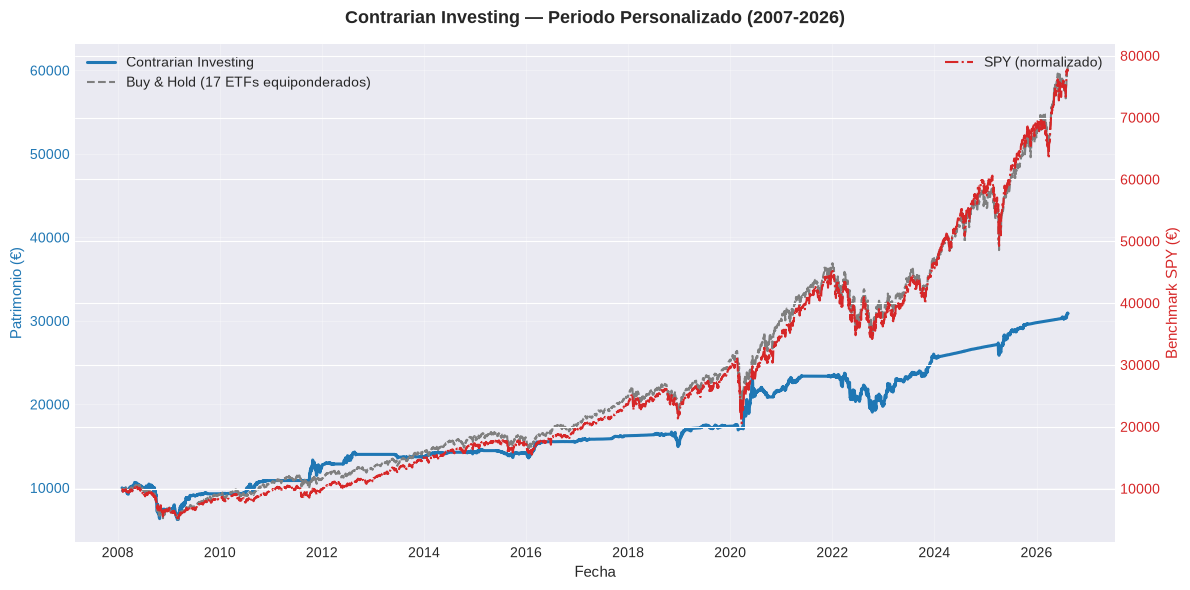


✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/contrarian_periodo_personalizado_2007_2026.png


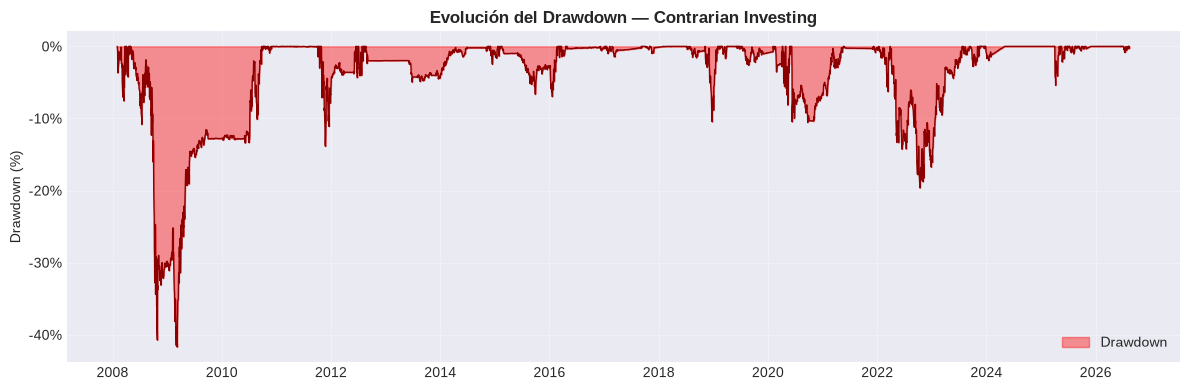

✅ Gráfico de drawdown guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/contrarian_periodo_personalizado_2007_2026_drawdown.png


In [10]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 8: VISUALIZACIÓN Y GUARDADO DE GRÁFICOS
# # ==============================================================================

# %%
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN Y GUARDADO DE GRÁFICOS
# ==============================================================================

# Estilo
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('seaborn-darkgrid')

# --- Gráfico principal: Equity Curve ---
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje izquierdo: Estrategia vs Buy & Hold
color_estrategia = 'tab:blue'
color_bh = 'tab:gray'
ax1.set_xlabel('Fecha', fontsize=11)
ax1.set_ylabel('Patrimonio (€)', color=color_estrategia, fontsize=11)
ax1.plot(serie_pat.index, serie_pat,
         label='Contrarian Investing', color=color_estrategia, lw=2.2)
ax1.plot(serie_bh.index, serie_bh,
         label='Buy & Hold (17 ETFs equiponderados)', color=color_bh, lw=1.5, ls='--')
ax1.tick_params(axis='y', labelcolor=color_estrategia)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)

# Eje derecho: Benchmark (SPY) normalizado
if serie_bmk is not None:
    ax2 = ax1.twinx()
    color_bench = 'tab:red'
    # Normalizar benchmark al mismo capital inicial
    bench_norm = serie_bmk
    ax2.set_ylabel(f'Benchmark {BENCHMARK} (€)', color=color_bench, fontsize=11)
    ax2.plot(bench_norm.index, bench_norm, label=f'{BENCHMARK} (normalizado)',
             color=color_bench, lw=1.5, ls='-.')
    ax2.tick_params(axis='y', labelcolor=color_bench)
    ax2.legend(loc='upper right', fontsize=10)

# Título dinámico
titulo = f'Contrarian Investing — {nombre_evento} ({fecha_ini[:4]}-{fecha_fin[:4]})'
plt.title(titulo, fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

# --- Guardar gráfico principal ---
nombre_archivo = f"contrarian_{nombre_evento.replace(' ', '_')}_{fecha_ini[:4]}_{fecha_fin[:4]}".lower()
ruta_guardado = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / f"{nombre_archivo}.png"  # ← AÑADIR Path()
fig.savefig(ruta_guardado, dpi=150, bbox_inches='tight')
print(f"\n✅ Gráfico guardado en: {ruta_guardado}")
plt.close()

# --- Gráfico secundario: Drawdown ---
fig2, ax = plt.subplots(figsize=(12, 4))
drawdown = (serie_pat / serie_pat.cummax()) - 1
ax.fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.4, label='Drawdown')
ax.plot(drawdown.index, drawdown, color='darkred', lw=1)
ax.set_title('Evolución del Drawdown — Contrarian Investing', fontsize=12, fontweight='bold')
ax.set_ylabel('Drawdown (%)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.grid(True, alpha=0.3)
ax.legend()
fig2.tight_layout()
plt.show()

ruta_dd = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / f"{nombre_archivo}_drawdown.png"  # ← AÑADIR Path()
fig2.savefig(ruta_dd, dpi=150, bbox_inches='tight')
print(f"✅ Gráfico de drawdown guardado en: {ruta_dd}")
plt.close()

## BLOQUE 9: ANÁLISIS DE CORRELACIÓN FINAL


🔗 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO CONTRARIAN

📊 TABLA DE CORRELACIONES (Retornos Diarios)
                           SPDR_S&P_500  Invesco_QQQ  Russell_2000_Small_Cap  Technology_SPDR  Financials_SPDR  Energy_SPDR  Healthcare_SPDR  Industrial_SPDR  Consumer_Staples_SPDR  Utilities_SPDR  Materials_SPDR  Consumer_Disc_SPDR  MSCI_EAFE_Developed  MSCI_Emerging_Markets  iShares_20+_Year_Treasury  Gold_ETF  Short_Treasury_ETF
SPDR_S&P_500                       1.00         0.92                    0.89             0.91             0.84         0.72             0.80             0.90                   0.73            0.64            0.85                0.89                 0.89                   0.82                      -0.31      0.06               -0.18
Invesco_QQQ                        0.92         1.00                    0.82             0.96             0.68         0.56             0.70             0.79                   0.61            0.50            0.74                0.87    

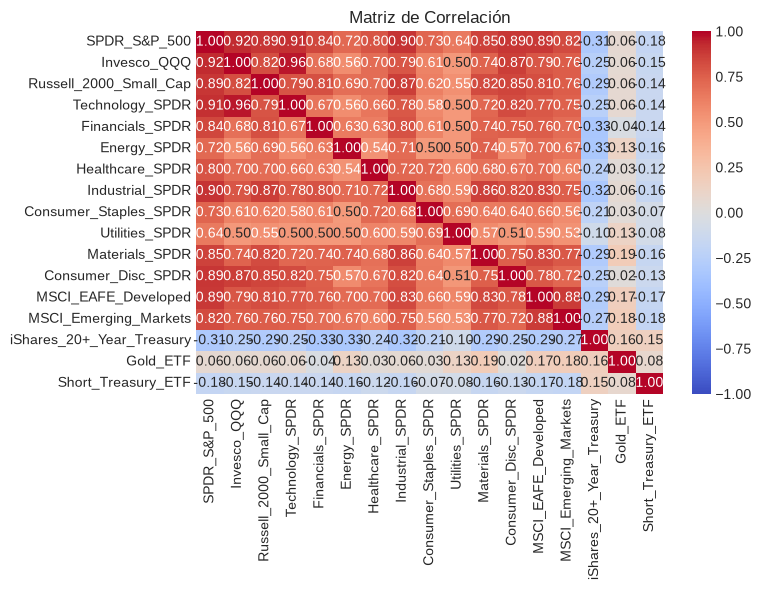


✅ Análisis de correlación completado.
   • Úsalo para identificar clusters de sectores altamente correlacionados.
   • Un universo contrarian ideal debe tener baja correlación interna
     para que la diversificación entre perdedores sea efectiva.


In [11]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 9: ANÁLISIS DE CORRELACIÓN FINAL
# # ==============================================================================

# %%
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE CORRELACIÓN FINAL
# ==============================================================================

print("\n" + "="*70)
print("🔗 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO CONTRARIAN")
print("="*70)

gestor.calcular_correlacion()

print("\n✅ Análisis de correlación completado.")
print("   • Úsalo para identificar clusters de sectores altamente correlacionados.")
print("   • Un universo contrarian ideal debe tener baja correlación interna")
print("     para que la diversificación entre perdedores sea efectiva.")

## BLOQUE 10: COMPARATIVA DE ESCENARIOS

,CAGR,Vol,Sharpe,MaxDD,Final €,Expo,Ops,Win-rate
v2 (sin retraso de señal),6.28%,13.76%,0.31,-38.8%,"30,855",29%,114,63%
v3 base (config del Bloque 0),6.29%,13.34%,0.32,-41.7%,"30,901",28%,115,65%
+ régimen SPY>SMA200 (bloquea entradas),2.91%,3.50%,0.26,-5.5%,"16,998",11%,43,72%
+ régimen y liquida posiciones,2.52%,3.38%,0.15,-6.3%,"15,839",10%,44,66%
+ excluir SPY de candidatos,6.28%,13.31%,0.32,-43.1%,"30,848",28%,113,66%
+ estabilización 5 d,3.46%,7.72%,0.19,-23.2%,"18,752",12%,47,68%
+ RSI mínimo 5 d,5.29%,15.00%,0.22,-50.4%,"25,931",32%,131,63%
"Defensivo (-30 %, RSI 30, 6 m)",3.03%,4.91%,0.21,-12.1%,"17,365",5%,9,78%
(ref) SPY buy & hold,11.75%,19.76%,0.49,-51.5%,"78,088",100%,0,—
(ref) SHV buy & hold (cash),1.38%,0.33%,—,-0.5%,"12,893",0%,0,—


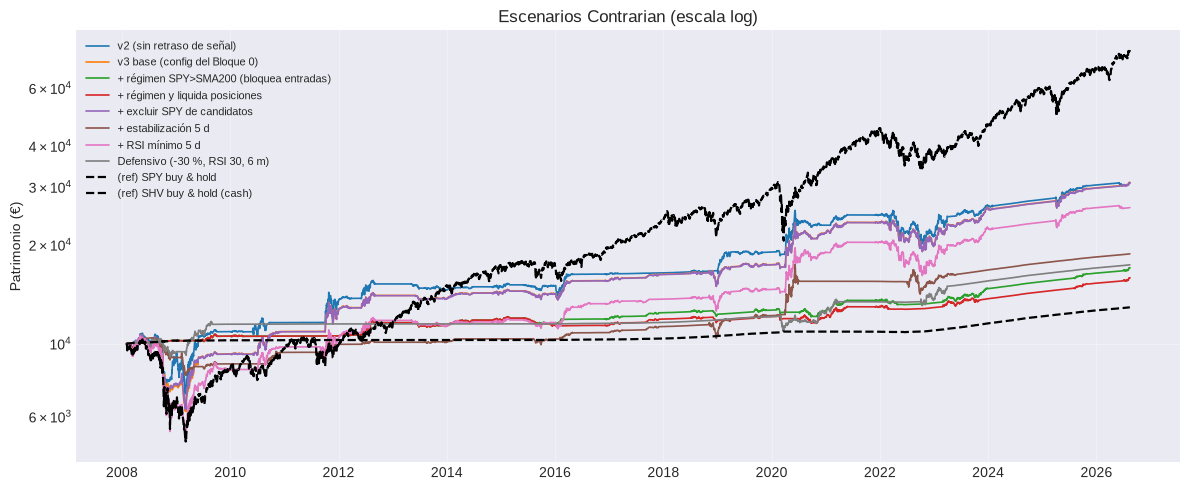

✅ Guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/contrarian_escenarios.png

Lectura: compara con las dos referencias. SPY = renta variable pura; SHV = lo que daría no hacer nada. Un escenario con poca exposición ('Expo') y CAGR cercano al de SHV solo está parado, no selecciona. Y una sola ejecución histórica no demuestra nada (Bloques 11 y 12).


In [12]:
# %%
# ==============================================================================
# BLOQUE 10: COMPARATIVA DE ESCENARIOS (cada uno = CFG_BASE + override)
# ==============================================================================
ESCENARIOS = {
    'v2 (sin retraso de señal)':          dict(retraso_senal_dias=0),
    'v3 base (config del Bloque 0)':      dict(),
    '+ régimen SPY>SMA200 (bloquea entradas)': dict(usar_regimen=True),
    '+ régimen y liquida posiciones':     dict(usar_regimen=True, regimen_cierra_posiciones=True),
    '+ excluir SPY de candidatos':        dict(excluir_spy=True),
    '+ estabilización 5 d':               dict(estabilizacion_dias=5),
    '+ RSI mínimo 5 d':                   dict(rsi_lookback_dias=5),
    'Defensivo (-30 %, RSI 30, 6 m)':     dict(umbral_drawdown=-0.30, umbral_rsi=30.0, holding_meses=6, stop_loss_pct=None),
}

tabla_esc, series_esc = comparar_escenarios(
    MotorBacktestDinamico, gestor.precios_ajustados, gestor.rentabilidades_diarias,
    CFG_BASE, ESCENARIOS, cash_columna, columna_spy,
    coste=COSTE_TRANSACCION * 2, fecha_inicio_operativa=fecha_ini, capital=CAPITAL_INICIAL)

fmt = {'CAGR': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}', 'MaxDD': '{:.1%}',
       'Final €': '{:,.0f}', 'Expo': '{:.0%}', 'Ops': '{:.0f}', 'Win-rate': '{:.0%}'}   # Expo = % medio del capital fuera de SHV
try:
    from IPython.display import display
    display(tabla_esc.style.format(fmt, na_rep='—'))
except Exception:
    print(tabla_esc.round(3).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
for nombre, s_ in series_esc.items():
    ref = nombre.startswith('(ref)')
    ax.plot(s_.index, s_, label=nombre, lw=1.6 if ref else 1.2, ls='--' if ref else '-', color='black' if ref else None)
ax.set_yscale('log'); ax.set_title('Escenarios Contrarian (escala log)'); ax.set_ylabel('Patrimonio (€)')
ax.legend(fontsize=8, loc='upper left'); ax.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()
ruta_esc = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "contrarian_escenarios.png"
fig.savefig(ruta_esc, dpi=150, bbox_inches='tight'); plt.close()
print(f"✅ Guardado en: {ruta_esc}")
print("\nLectura: compara con las dos referencias. SPY = renta variable pura; SHV = lo que daría no hacer nada. "
      "Un escenario con poca exposición ('Expo') y CAGR cercano al de SHV solo está parado, no selecciona. "
      "Y una sola ejecución histórica no demuestra nada (Bloques 11 y 12).")


## BLOQUE 11: BARRIDO DE PARÁMETROS (en muestra vs. fuera de muestra)

In [13]:
# %%
# ==============================================================================
# BLOQUE 11: BARRIDO DE PARÁMETROS — cada combinación se evalúa ANTES y DESPUÉS de FECHA_CORTE_OOS
# ==============================================================================
RUN_BARRIDO      = True
FECHA_CORTE_OOS  = '2017-01-01'     # IS = antes de esta fecha; OOS = desde esta fecha
GRID = {
    'top_n':           [2, 3, 5],            # nº de slots = cuánto capital recibe cada señal (1/top_n)
    'umbral_drawdown': [-0.10, -0.15, -0.20, -0.30],
    'umbral_rsi':      [30.0, 45.0],
    'holding_meses':   [3, 6],
    'stop_loss_pct':   [None, -0.10],
}   # 3×4×2×2×2 = 96 ejecuciones (~0,5 s cada una)

if RUN_BARRIDO:
    import itertools
    n_runs = int(np.prod([len(v) for v in GRID.values()]))
    print(f"⏳ Barrido de {n_runs} combinaciones (corte IS/OOS: {FECHA_CORTE_OOS})...")
    barrido = barrido_parametros(
        MotorBacktestDinamico, gestor.precios_ajustados, gestor.rentabilidades_diarias,
        CFG_BASE, GRID, cash_columna, columna_spy,
        coste=COSTE_TRANSACCION * 2, fecha_inicio_operativa=fecha_ini,
        fecha_corte=FECHA_CORTE_OOS, capital=CAPITAL_INICIAL)

    fmt_b = {c: '{:.2%}' for c in barrido.columns if c.startswith('CAGR')}
    fmt_b.update({c: '{:.1%}' for c in barrido.columns if c.startswith('MaxDD')})
    fmt_b.update({c: '{:.2f}' for c in barrido.columns if c.startswith('Sharpe')})
    fmt_b['Expo'] = '{:.0%}'
    top = barrido.sort_values('Sharpe_IS', ascending=False).head(10)
    print("\n🏆 Top 10 por Sharpe EN MUESTRA (mira cuánto se conserva fuera de muestra):")
    try:
        display(top.style.format(fmt_b, na_rep='sin stop'))
    except Exception:
        print(top.round(3).to_string())

    rho = barrido['Sharpe_IS'].corr(barrido['Sharpe_OOS'], method='spearman')
    print(f"\n📐 Correlación de rangos (Spearman) Sharpe IS vs OOS: {rho:+.2f}")
    print("   ≈ 0  → el barrido está ajustando ruido: la 'mejor' combinación en muestra no predice la siguiente.")
    print("   > 0.4 → hay cierta estabilidad; busca zonas amplias de buenos resultados, no un punto aislado.")

    # Sensibilidad media por parámetro (Sharpe OOS)
    print("\n📊 Sharpe OOS medio por valor de parámetro:")
    for p in GRID:
        print(f"   • {p}: " + " | ".join(f"{v}: {g['Sharpe_OOS'].mean():.2f}"
                                          for v, g in barrido.assign(**{p: barrido[p].astype(object).where(barrido[p].notna(), 'None')}).groupby(p)))
else:
    print("RUN_BARRIDO = False: barrido omitido.")


⏳ Barrido de 96 combinaciones (corte IS/OOS: 2017-01-01)...

🏆 Top 10 por Sharpe EN MUESTRA (mira cuánto se conserva fuera de muestra):


,top_n,umbral_drawdown,umbral_rsi,holding_meses,stop_loss_pct,CAGR_IS,Sharpe_IS,MaxDD_IS,CAGR_OOS,Sharpe_OOS,MaxDD_OOS,Expo,Ops
79,5,-0.150000,45.000000,6,-0.100000,7.58%,0.35,-41.5%,11.04%,0.78,-20.7%,42%,91
71,5,-0.100000,45.000000,6,-0.100000,7.03%,0.31,-41.0%,7.60%,0.39,-32.5%,60%,129
69,5,-0.100000,45.000000,3,-0.100000,6.96%,0.30,-40.4%,8.30%,0.46,-33.9%,46%,185
78,5,-0.150000,45.000000,6,sin stop,7.14%,0.28,-44.6%,9.03%,0.62,-20.3%,44%,82
70,5,-0.100000,45.000000,6,sin stop,6.94%,0.26,-45.0%,11.04%,0.58,-35.8%,63%,115
0,2,-0.100000,30.000000,3,sin stop,4.95%,0.26,-15.4%,4.09%,0.15,-46.1%,17%,26
1,2,-0.100000,30.000000,3,-0.100000,4.95%,0.26,-15.4%,2.29%,0.02,-41.2%,17%,27
9,2,-0.150000,30.000000,3,-0.100000,4.88%,0.26,-15.4%,5.70%,0.51,-12.0%,12%,18
8,2,-0.150000,30.000000,3,sin stop,4.88%,0.26,-15.4%,4.48%,0.27,-30.7%,12%,18
5,2,-0.100000,45.000000,3,-0.100000,6.83%,0.23,-45.2%,11.58%,0.54,-40.0%,64%,103



📐 Correlación de rangos (Spearman) Sharpe IS vs OOS: +0.11
   ≈ 0  → el barrido está ajustando ruido: la 'mejor' combinación en muestra no predice la siguiente.
   > 0.4 → hay cierta estabilidad; busca zonas amplias de buenos resultados, no un punto aislado.

📊 Sharpe OOS medio por valor de parámetro:
   • top_n: 2: 0.38 | 3: 0.41 | 5: 0.39
   • umbral_drawdown: -0.3: 0.30 | -0.2: 0.43 | -0.15: 0.51 | -0.1: 0.32
   • umbral_rsi: 30.0: 0.27 | 45.0: 0.51
   • holding_meses: 3: 0.31 | 6: 0.47
   • stop_loss_pct: -0.1: 0.39 | None: 0.40


## BLOQUE 12: TEST PLACEBO — ¿la selección contrarian supera al azar?

⏳ Test placebo: 200 simulaciones con el calendario de entradas de la estrategia real...
   ... 25/200 simulaciones
   ... 50/200 simulaciones
   ... 75/200 simulaciones
   ... 100/200 simulaciones
   ... 125/200 simulaciones
   ... 150/200 simulaciones
   ... 175/200 simulaciones
   ... 200/200 simulaciones

📊 Estrategia real vs distribución placebo (p_valor = proporción de placebos ≥ real; menor = más mérito):


,real,placebo_media,placebo_p5,placebo_p50,placebo_p95,p_valor
CAGR,0.0629,0.0526,0.0397,0.0529,0.0657,0.100
Sharpe,0.3214,0.3079,0.1855,0.3139,0.4162,0.448
MaxDD,-0.4171,-0.3762,-0.4350,-0.3793,-0.3021,0.846
Ret_medio_op,0.0525,0.0425,0.0305,0.0428,0.0529,0.070
Win-rate,0.6522,0.6701,0.6213,0.6696,0.7157,0.746
Expo,0.2848,0.2835,0.2785,0.2838,0.2878,0.333
Ops,115.0000,111.8800,110.0000,112.0000,114.0000,0.020


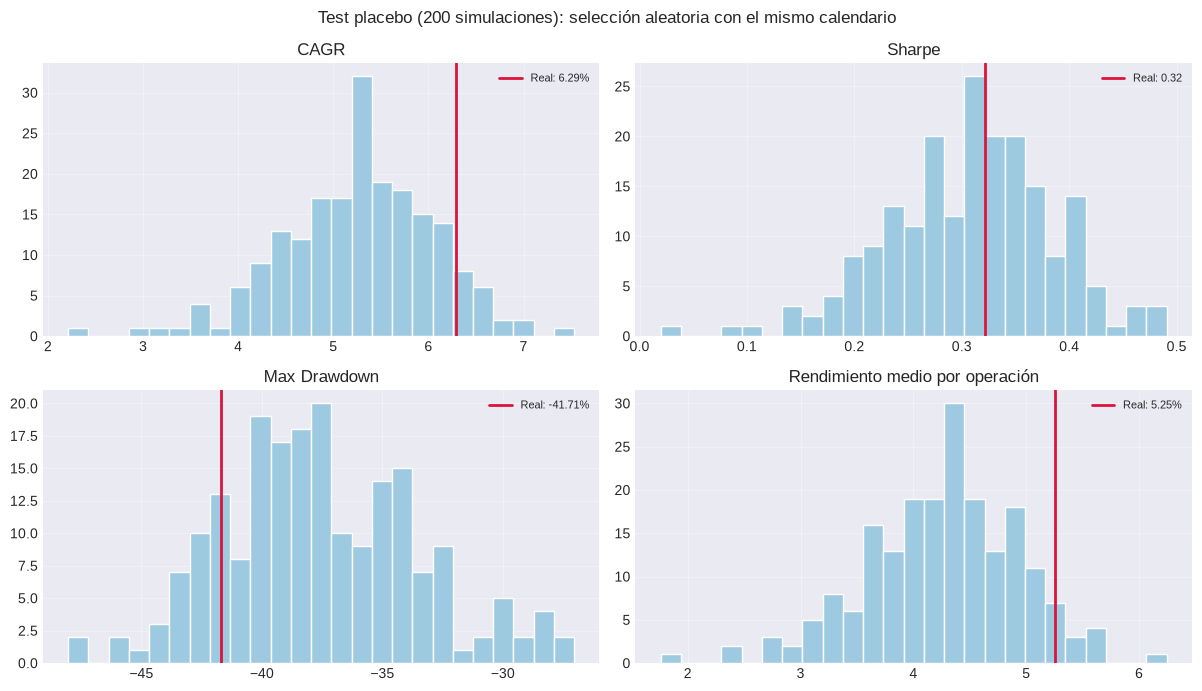

✅ Guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/contrarian_placebo.png

🔎 Lectura (cada p-valor es unilateral y los estadísticos están muy correlacionados entre sí):
   • Rendimiento medio por operación : p = 0.070 → indicio débil
   • CAGR                            : p = 0.100 → indicio débil
   • Sharpe                          : p = 0.448 → no distinguible del azar
   • Max Drawdown                    : p = 0.846 → no distinguible del azar

   Exposición media: real 28% vs placebo 28% (si difieren mucho, la comparación no es limpia).
   Cautelas: es UNA configuración (la del Bloque 0, elegida tras ver resultados), UNA serie histórica y pocos episodios independientes (2008-09, 2020, 2022). Un p-valor bajo no prueba nada definitivo; uno alto significa que no hay evidencia de selección, aunque con tan pocos episodios la prueba tiene poca potencia (ausencia de evidencia no es evidencia de ausencia).


In [14]:
# %%
# ==============================================================================
# BLOQUE 12: TEST PLACEBO DE SELECCIÓN
# Mismo calendario de entradas, mismo nº de posiciones, holding, stop, régimen y costes que la estrategia
# real; lo único que cambia es QUÉ ETF se compra (al azar entre los que tienen datos válidos).
# Si la estrategia real no queda claramente por encima de esa distribución, el criterio contrarian
# (drawdown + RSI + peor 12 m) no está aportando selección: solo estás más o menos invertido.
# ==============================================================================
RUN_PLACEBO     = True
N_PLACEBO       = 200      # ~0,4 s por simulación
SEMILLA_PLACEBO = 42

if RUN_PLACEBO:
    print(f"⏳ Test placebo: {N_PLACEBO} simulaciones con el calendario de entradas de la estrategia real...")
    resumen_placebo, sims_placebo, real_placebo = test_placebo(
        MotorBacktestDinamico, gestor.precios_ajustados, gestor.rentabilidades_diarias,
        CFG_BASE, cash_columna, columna_spy,
        coste=COSTE_TRANSACCION * 2, fecha_inicio_operativa=fecha_ini,
        n_sim=N_PLACEBO, semilla=SEMILLA_PLACEBO, capital=CAPITAL_INICIAL)

    fmt_p = {'real': '{:.4f}', 'placebo_media': '{:.4f}', 'placebo_p5': '{:.4f}', 'placebo_p50': '{:.4f}',
             'placebo_p95': '{:.4f}', 'p_valor': '{:.3f}'}
    print("\n📊 Estrategia real vs distribución placebo (p_valor = proporción de placebos ≥ real; menor = más mérito):")
    try:
        display(resumen_placebo.style.format(fmt_p, na_rep='—'))
    except Exception:
        print(resumen_placebo.round(4).to_string())

    fig, axs = plt.subplots(2, 2, figsize=(12, 7))
    for ax, (col, titulo, pct) in zip(axs.ravel(), [('CAGR', 'CAGR', True), ('Sharpe', 'Sharpe', False),
                                                    ('MaxDD', 'Max Drawdown', True), ('Ret_medio_op', 'Rendimiento medio por operación', True)]):
        x = sims_placebo[col].dropna() * (100 if pct else 1)
        v = real_placebo[col] * (100 if pct else 1)
        ax.hist(x, bins=25, color='#9ecae1', edgecolor='white')
        ax.axvline(v, color='crimson', lw=2, label=f"Real: {v:.2f}{'%' if pct else ''}")
        ax.set_title(titulo); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.suptitle(f'Test placebo ({len(sims_placebo)} simulaciones): selección aleatoria con el mismo calendario', fontsize=12)
    fig.tight_layout(); plt.show()
    ruta_pl = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "contrarian_placebo.png"
    fig.savefig(ruta_pl, dpi=150, bbox_inches='tight'); plt.close()
    print(f"✅ Guardado en: {ruta_pl}")

    def _veredicto(p):
        return ("por encima del azar" if p <= 0.05 else "indicio débil" if p <= 0.20 else "no distinguible del azar")
    print("\n🔎 Lectura (cada p-valor es unilateral y los estadísticos están muy correlacionados entre sí):")
    for k_, nombre in [('Ret_medio_op', 'Rendimiento medio por operación'), ('CAGR', 'CAGR'),
                       ('Sharpe', 'Sharpe'), ('MaxDD', 'Max Drawdown')]:
        p_ = resumen_placebo.loc[k_, 'p_valor']
        print(f"   • {nombre:<32}: p = {p_:.3f} → {_veredicto(p_)}")
    print(f"\n   Exposición media: real {real_placebo['Expo']:.0%} vs placebo {sims_placebo['Expo'].mean():.0%} "
          f"(si difieren mucho, la comparación no es limpia).")
    print("   Cautelas: es UNA configuración (la del Bloque 0, elegida tras ver resultados), UNA serie histórica y "
          "pocos episodios independientes (2008-09, 2020, 2022). Un p-valor bajo no prueba nada definitivo; "
          "uno alto significa que no hay evidencia de selección, aunque con tan pocos episodios la prueba "
          "tiene poca potencia (ausencia de evidencia no es evidencia de ausencia).")
else:
    print("RUN_PLACEBO = False: test placebo omitido.")


## BLOQUE 13: CONCLUSIONES PEDAGÓGICAS Y CIERRE

In [15]:
# %%
# ==============================================================================
# BLOQUE 13: CONCLUSIONES — generadas a partir de los resultados reales de ESTA ejecución
# ==============================================================================
def _g(d, k, default=np.nan):
    try:
        return float(d.get(k, default))
    except Exception:
        return default

cagr_s, cagr_b = _g(metricas_reb, 'CAGR'), _g(metricas_bh, 'CAGR')
dd_s, dd_b     = _g(metricas_reb, 'Max Drawdown'), _g(metricas_bh, 'Max Drawdown')
sh_s, sh_b     = _g(metricas_reb, 'Sharpe'), _g(metricas_bh, 'Sharpe')
beta_s         = _g(metricas_reb, 'Beta')
ir             = _g(metricas_extras, 'Information Ratio')
wr             = _g(metricas_extras, 'Win-rate')
n_ops          = int(_g(metricas_extras, 'Operaciones Totales', 0))
pct_con_senal  = float((diag > 0).mean())

def _si(c): return "SÍ" if c else "NO"

expo_media = float(np.mean(estado_final.get('exposicion', [np.nan])))
try:
    cagr_shv = float(tabla_esc.loc['(ref) SHV buy & hold (cash)', 'CAGR'])
except Exception:
    cagr_shv = np.nan

if 'resumen_placebo' in globals():
    _p = resumen_placebo['p_valor']
    def _v(p): return "por encima del azar" if p <= 0.05 else "indicio débil" if p <= 0.20 else "no distinguible del azar"
    txt_placebo = (f"  • Rend. medio por operación: real {resumen_placebo.loc['Ret_medio_op','real']:.2%} vs placebo "
                   f"{resumen_placebo.loc['Ret_medio_op','placebo_media']:.2%} (p = {_p['Ret_medio_op']:.3f} → {_v(_p['Ret_medio_op'])})\n"
                   f"  • CAGR: p = {_p['CAGR']:.3f} → {_v(_p['CAGR'])} | Sharpe: p = {_p['Sharpe']:.3f} → {_v(_p['Sharpe'])}")
else:
    txt_placebo = "  (test placebo no ejecutado: RUN_PLACEBO = False)"

print("\n" + "=" * 70)
print("🎓 CONCLUSIONES DEL CAPÍTULO 2: CONTRARIAN INVESTING (datos de esta ejecución)")
print("=" * 70)
print(f"""
Configuración: perfil '{PERFIL}' | DD ≤ {UMBRAL_DRAWDOWN:.0%} | RSI ≤ {UMBRAL_RSI:.0f} | holding {HOLDING_MESES} m | \
stop {f'{STOP_LOSS_PCT:.0%}' if STOP_LOSS_PCT is not None else 'no'} | {TOP_N_PERDEDORES} slots | retraso señal {RETRASO_SENAL_DIAS} d
Periodo: {serie_pat.index[0].date()} → {serie_pat.index[-1].date()}

RESULTADO FRENTE AL BUY & HOLD
  • CAGR:          {cagr_s:7.2%}  vs  {cagr_b:7.2%}   → ¿bate al B&H? {_si(cagr_s > cagr_b)}
  • Max Drawdown:  {dd_s:7.1%}  vs  {dd_b:7.1%}   → ¿reduce el drawdown? {_si(dd_s > dd_b)}
  • Sharpe:        {sh_s:7.2f}  vs  {sh_b:7.2f}   → ¿mejor ajustado al riesgo? {_si(sh_s > sh_b)}
  • Beta vs {BENCHMARK}: {beta_s:.2f} | Alpha de Jensen: {alpha_jensen:+.2%} | Information Ratio: {ir:+.2f}
  • Operaciones: {n_ops} | Win-rate: {wr:.1%} | Meses con señal: {pct_con_senal:.0%}
  • Exposición media (fuera de SHV): {expo_media:.0%} | CAGR de SHV (no hacer nada): {cagr_shv:.2%}

SELECCIÓN FRENTE AL AZAR (Bloque 12, mismo calendario de entradas)
{txt_placebo}

LECTURA
  1. Los filtros (drawdown + RSI) miden el pánico, no su final: en una crisis sistémica casi todos los
     ETFs los cumplen A LA VEZ y la estrategia compra mientras el mercado sigue cayendo. Revisa el log
     de operaciones y el drawdown máximo: si coincide con una crisis, ahí está el 'cuchillo'.
  2. Un alpha 'positivo' con beta baja puede ser solo tiempo en cash. Usa el alpha de Jensen (con rf)
     y el Information Ratio antes de concluir que hay valor añadido.
  3. Si no bate al B&H en CAGR ni reduce el drawdown, no es un satélite defensivo: solo es una
     estrategia cara (turnover) con poca exposición. Eso también es un resultado válido del capítulo.
  4. Bloque 10: referencias SPY y SHV. Bloque 11: estabilidad IS/OOS del barrido. Bloque 12: placebo, que es
     lo único que separa "saber elegir" de "estar más o menos invertido". Limitaciones: una sola serie histórica,
     pocos episodios independientes y datos desde 2007 (SHV).
""")
print("=" * 70)
print("✅ CAPÍTULO 2 COMPLETADO")
print("=" * 70)



🎓 CONCLUSIONES DEL CAPÍTULO 2: CONTRARIAN INVESTING (datos de esta ejecución)

Configuración: perfil 'agresivo' | DD ≤ -15% | RSI ≤ 45 | holding 3 m | stop -10% | 5 slots | retraso señal 1 d
Periodo: 2008-02-01 → 2026-08-14

RESULTADO FRENTE AL BUY & HOLD
  • CAGR:            6.28%  vs   10.20%   → ¿bate al B&H? NO
  • Max Drawdown:   -41.7%  vs   -40.9%   → ¿reduce el drawdown? NO
  • Sharpe:           0.32  vs     0.52   → ¿mejor ajustado al riesgo? NO
  • Beta vs SPY: 0.44 | Alpha de Jensen: -0.03% | Information Ratio: -0.37
  • Operaciones: 115 | Win-rate: 65.2% | Meses con señal: 34%
  • Exposición media (fuera de SHV): 28% | CAGR de SHV (no hacer nada): 1.38%

SELECCIÓN FRENTE AL AZAR (Bloque 12, mismo calendario de entradas)
  • Rend. medio por operación: real 5.25% vs placebo 4.25% (p = 0.070 → indicio débil)
  • CAGR: p = 0.100 → indicio débil | Sharpe: p = 0.448 → no distinguible del azar

LECTURA
  1. Los filtros (drawdown + RSI) miden el pánico, no su final: en una crisis 